In [1]:
from matplotlib import pyplot as plt
import numpy as np 
import os
import pandas as pd 
from pathlib import Path

In [2]:
from scaling.utils import (
    get_pareto_frontier, get_final_points_from_curve_set,
    functional_form_L0, fit_parametric_form
)

In [3]:
import sys

sys.path.append(str(Path(os.getcwd()).parent))

from parametric_forms import PARAMETRIC_FORMS
from iterative_fits_L0_form import data_preprocess, build_surrogate, _print_fit_results

In [4]:
PLOT_PATH = Path(os.getcwd()).absolute().parent / "plots"
PLOT_PATH.mkdir(exist_ok=True, parents=True)

In [5]:
DATA_PATH = Path(os.getcwd()).absolute().parent / "data"

In [6]:
df = pd.read_csv(DATA_PATH / "all_points_clean.csv")

In [7]:
df["flops"] = 6 * df["N_approx"] * df["D"]

In [8]:
global_train_df, global_test_df_known, global_test_df_unknown = data_preprocess(
    df, held_out_type="C", held_out_C_lower=0.6
)
global_train_df.shape, global_test_df_known.shape, global_test_df_unknown.shape

((885, 16), (5, 16), (5, 6))

In [9]:
global_test_pareto = get_pareto_frontier(
    global_test_df_known,
    x_name="flops",
    y_name="loss",
)
global_test_pareto.shape, global_test_pareto.flops.max()

((2, 16), np.float64(3.06e+21))

In [10]:
_global_pareto = get_pareto_frontier(
    global_train_df,
    x_name="flops",
    y_name="loss",
)
global_data_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _global_pareto["flops"].values,
    _global_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)

In [11]:
INPUTS = ["N", "D", "lr", "gbsz"]

---

### Case A: low $C_{\text{max}}^{\text{obs}}$

In [12]:
C_FRAC_THRESHOLD=3/1000

In [13]:
# preprocess data
train_df, test_df_known, test_df_unknown = data_preprocess(
    df, held_out_type="C", held_out_C_lower=C_FRAC_THRESHOLD
)
train_df.shape, test_df_known.shape, train_df.flops.max(), test_df_known.flops.max()

((122, 16), (768, 16), np.float64(9.36e+18), np.float64(3.06e+21))

In [14]:
test_df_known = test_df_known.loc[list(set(test_df_known.index.values) - set(global_test_df_known.index.values))]
test_df_known.shape, test_df_known.flops.max()

((763, 16), np.float64(1.8e+21))

In [15]:
global_test_df_known

,job_name,N,N_approx,D,C,lr,gbsz,beta2,seed,iteration,train_samples,train_tokens,num_of_valid_seq,loss,loss_se,flops
330,dense_1_7B_xm01_lr0.0005_gbsz1024_beta20.95_200B,1713504256,1.700000e+09,2.000000e+11,2.056205e+21,0.0005,1024,0.95,1234,47684.0,48828416.0,2.000012e+11,204800.0,2.053338,0.0,2.040000e+21
340,dense_1_7B_xm01_lr0.001_gbsz1024_beta20.95_200B,1713504256,1.700000e+09,2.000000e+11,2.056205e+21,0.0010,1024,0.95,1234,47684.0,48828416.0,2.000012e+11,204800.0,2.057035,0.0,2.040000e+21
344,dense_1_7B_xm01_lr0.001_gbsz2048_beta20.95_200B,1713504256,1.700000e+09,2.000000e+11,2.056205e+21,0.0010,2048,0.95,1234,23842.0,48828416.0,2.000012e+11,204800.0,2.070433,0.0,2.040000e+21
345,dense_1_7B_xm01_lr0.001_gbsz2048_beta20.95_300B,1713504256,1.700000e+09,3.000000e+11,3.084308e+21,0.0010,2048,0.95,1234,35763.0,73242624.0,3.000018e+11,204800.0,2.038693,0.0,3.060000e+21
362,dense_1_7B_xm01_lr0.002_gbsz512_beta20.95_200B,1713504256,1.700000e+09,2.000000e+11,2.056205e+21,0.0020,512,0.95,1234,95368.0,48828416.0,2.000012e+11,204800.0,2.041586,0.0,2.040000e+21


In [16]:
_test_df_pareto = get_pareto_frontier(
    test_df_known,
    x_name="flops",
    y_name="loss",
)

In [17]:
# build GP
_pred, _mse, model = build_surrogate(
    np.log(train_df[INPUTS].values),
    # np.log(train_df["flops"].to_numpy())[:, None],
    train_df["loss"].to_numpy()[:, None],
    np.log(global_test_pareto[INPUTS].to_numpy()),
    model_type="gp",
    mean_form=None,
)
print(_pred)

[2.44602225 2.46897002]


In [18]:
INPUTS = ["N", "D", "lr", "gbsz"]

# ---- param fit on observed data only (parametric form still takes flops) ----
_train_pareto = get_pareto_frontier(train_df, x_name="flops", y_name="loss")
_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _train_pareto["flops"].values, np.log(_train_pareto["loss"].values),
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _best_params))

# ---- fantasize the held-out points with the surrogate over all INPUTS ----
_fantasized_pred = model.predict(np.log(test_df_known[INPUTS].to_numpy()))

# refitting the surrogate on observed + fantasized
fant_pred, fant_mse, fant_model = build_surrogate(
    np.log(np.vstack((train_df[INPUTS].to_numpy(), test_df_known[INPUTS].to_numpy()))),
    np.hstack((train_df["loss"].values, _fantasized_pred.flatten()))[:, None],
    np.log(global_test_pareto[INPUTS].to_numpy()),
    model_type="gp",
    mean_form=None,
)
print(fant_pred)

# ---- refitting the parametric form on observed + fantasized ----
_fant_train_pareto = get_pareto_frontier(
    pd.concat((train_df, test_df_known.assign(loss=_fantasized_pred.flatten()))),
    x_name="flops", y_name="loss",
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_train_pareto["flops"].values, np.log(_fant_train_pareto["loss"].values),
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _fant_best_params))

print("=" * 50)
print(len(_train_pareto), len(_fant_train_pareto))
print(f"best params on observed data only: {_best_params}")
print(f"best params on observed + predicted data: {_fant_best_params}")

[0.70055482 0.68317812]
[2.44604219 2.47006566]
[0.84192523 0.83883495]
4 17
best params on observed data only: [ 0.17215796  4.99869928 -0.10574559]
best params on observed + predicted data: [ 0.81889088 14.68005344 -0.35910709]


In [19]:
# param fits

### on observed data only
_train_pareto = get_pareto_frontier(
    train_df,
    x_name="flops",
    y_name="loss",
)
_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _train_pareto["flops"].values, _train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _best_params))

### on observed + predicted data
_fantasized_pred = model.predict(np.log(test_df_known[INPUTS].values))

# refitting
fant_pred, fant_mse, fant_model = build_surrogate(
    np.log(np.hstack((train_df.flops.values, test_df_known.flops.values))[:, None]),
    np.hstack((train_df["loss"].values, _fantasized_pred.flatten()))[:, None],
    np.log(global_test_pareto["flops"].to_numpy()),
    model_type="gp",
    mean_form=None,
)
print(fant_pred)

# reftting parametric form
_fant_train_pareto = get_pareto_frontier(
    pd.concat((train_df, test_df_known.assign(loss=_fantasized_pred.flatten()))),
    x_name="flops",
    y_name="loss",
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_train_pareto["flops"].values, _fant_train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
) 
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _fant_best_params))

print("=" * 50)
print(len(_train_pareto), len(_fant_train_pareto))
print(f"best params on observed data only: {_best_params}")
print(f"best params on observed + predicted data: {_fant_best_params}")

[1.95157906 1.91338769]
[2.3785584  2.61499956]
[2.2452525  2.21852239]
4 17
best params on observed data only: [ 1.38629436 12.09717391 -0.2238843 ]
best params on observed + predicted data: [ 1.38629436  7.36265357 -0.1155223 ]


/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_39500/1947517848.py:12: UserWarning: You passed an edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")


<Figure size 640x480 with 0 Axes>

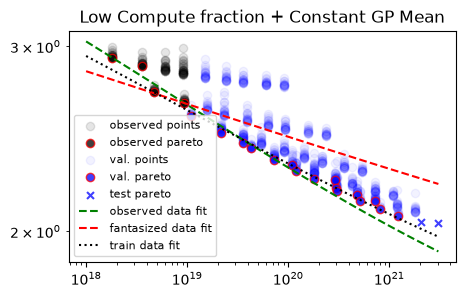

In [20]:
plt.clf()

plt.figure(figsize=(5,3))

# mark observed points
plt.scatter(train_df["flops"], train_df["loss"], color="black", label="observed points", alpha=0.1)
plt.scatter(_train_pareto["flops"], _train_pareto["loss"], color="black", label="observed pareto", alpha=0.75, edgecolor="red")

# mark test points
plt.scatter(test_df_known["flops"], test_df_known["loss"], color="blue", label="val. points", alpha=0.05)
plt.scatter(_test_df_pareto["flops"], _test_df_pareto["loss"], color="blue", label="val. pareto", alpha=0.75, edgecolor="red")
plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")

# comparing predictions
_flops = np.logspace(18, np.log10(global_test_pareto["flops"].max()), 100)

plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _best_params),
    color="green", label="observed data fit", linestyle="--"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _fant_best_params),
    color="red", label="fantasized data fit", linestyle="--"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, global_data_params),  #all_data_params),
    color="black", label="train data fit", linestyle=":"
)

plt.plot(
    
)
# plt.plot(
#     # global_test_pareto["flops"],
#     _flops,
#     model.predict(np.log(_flops)[:, None]),
#     color="orange", label="GP prediction", linestyle="-"
# )
# plt.plot(
#     _flops,
#     fant_model.predict(np.log(_flops)[:, None]),
#     color="purple", label="Fantasized GP prediction", linestyle="-."
# )

plt.xscale("log")
plt.yscale("log")
plt.legend(ncol=1, loc="lower left", fontsize=8)

plt.title(f"Low Compute fraction + Constant GP Mean")

plt.savefig(PLOT_PATH / f"low_C_std_gp.pdf", dpi=300, bbox_inches="tight")

#### Changing GP mean

In [21]:
# build GP
_pred, _mse, model = build_surrogate(
    np.log(_train_pareto[INPUTS].values),
    _train_pareto.loss.to_numpy()[:, None],
    # np.log(train_df["flops"].to_numpy())[:, None],
    # train_df["loss"].to_numpy()[:, None],
    np.log(global_test_pareto[INPUTS].values),
    model_type="gp",
    mean_form="L0",
)
print(_pred)

### on observed + predicted data
_fantasized_pred = model.predict(np.log(test_df_known[INPUTS].values))

_new_df = pd.concat((train_df, test_df_known.assign(loss=_fantasized_pred.flatten())))
_new_df_pareto = get_pareto_frontier(
    _new_df,
    x_name="flops",
    y_name="loss",
)

# refitting
fant_pred, fant_mse, fant_model = build_surrogate(
    np.log(_new_df_pareto[INPUTS].values),
    _new_df_pareto.loss.values[:, None],
    np.log(global_test_pareto[INPUTS].values),
    model_type="gp",
    mean_form="L0",
)
print(fant_pred)

# reftting parametric form
_fant_train_pareto = get_pareto_frontier(
    _new_df,
    x_name="flops",
    y_name="loss",
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_train_pareto["flops"].values, _fant_train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
) 
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _fant_best_params))

print("=" * 50)
print(len(_train_pareto), len(_fant_train_pareto))
print(f"best params on observed data only: {_best_params}")
print(f"best params on observed + predicted data: {_fant_best_params}")

[2.35261098 2.34325398]
[2.33679837 2.33663471]
[2.1960142  2.16683767]
4 15
best params on observed data only: [ 1.38629436 12.09717391 -0.2238843 ]
best params on observed + predicted data: [ 1.38629436  8.04518504 -0.13120622]


/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_39500/1471725008.py:12: UserWarning: You passed an edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")


<Figure size 640x480 with 0 Axes>

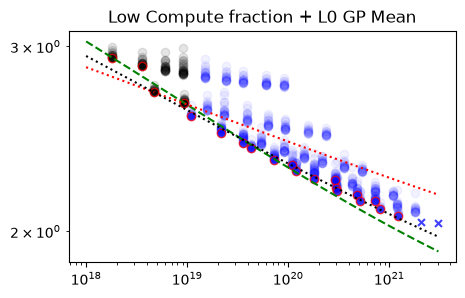

In [22]:
plt.clf()

plt.figure(figsize=(5,3))

# mark observed points
plt.scatter(train_df["flops"], train_df["loss"], color="black", label="observed points", alpha=0.1)
plt.scatter(_train_pareto["flops"], _train_pareto["loss"], color="black", label="observed pareto", alpha=0.75, edgecolor="red")

# mark test points
plt.scatter(test_df_known["flops"], test_df_known["loss"], color="blue", label="val. points", alpha=0.05)
plt.scatter(_test_df_pareto["flops"], _test_df_pareto["loss"], color="blue", label="val. pareto", alpha=0.75, edgecolor="red")
plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")

# comparing predictions
_flops = np.logspace(18, np.log10(global_test_pareto["flops"].max()), 100)

plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _best_params),
    color="green", label="observed data fit", linestyle="--"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _fant_best_params),
    color="red", label="observed + predicted data fit", linestyle=":"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, global_data_params),  #all_data_params),
    color="black", label="train data fit", linestyle=":"
)
# plt.plot(
#     _flops,
#     model.predict(np.log(_flops)[:, None]),
#     color="orange", label="GP prediction", linestyle="-"
# )
# plt.plot(
#     _flops,
#     fant_model.predict(np.log(_flops)[:, None]),
#     color="purple", label="Fantasized GP prediction", linestyle="-."
# )

plt.xscale("log")
plt.yscale("log")
# plt.legend(ncol=2, loc="upper right")
plt.title(f"Low Compute fraction + L0 GP Mean")

plt.savefig(PLOT_PATH / f"low_C_L0_gp.pdf", dpi=300, bbox_inches="tight")

---

### Case B: high $C_{\text{max}}^{\text{obs}}$

In [23]:
C_FRAC_THRESHOLD=1/10

In [24]:
# preprocess data
train_df, test_df_known, test_df_unknown = data_preprocess(
    df, held_out_type="C", held_out_C_lower=C_FRAC_THRESHOLD
)
train_df.shape, test_df_known.shape, train_df.flops.max(), test_df_known.flops.max()

((689, 16), (201, 16), np.float64(3e+20), np.float64(3.06e+21))

In [25]:
test_df_known = test_df_known.loc[list(set(test_df_known.index.values) - set(global_test_df_known.index.values))]
test_df_known.shape, test_df_known.flops.max()

((196, 16), np.float64(1.8e+21))

In [26]:
_test_df_pareto = get_pareto_frontier(
    test_df_known,
    x_name="flops",
    y_name="loss",
)

In [27]:
# build GP
_pred, _mse, model = build_surrogate(
    np.log(train_df[INPUTS].values),
    # np.log(train_df["flops"].to_numpy())[:, None],
    train_df["loss"].to_numpy()[:, None],
    np.log(global_test_pareto[INPUTS].values),
    model_type="gp",
    mean_form=None,
)
print(_pred)

[2.0735192  2.07689283]


In [28]:
# param fits

### on observed data only
_train_pareto = get_pareto_frontier(
    train_df,
    x_name="flops",
    y_name="loss",
)
_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _train_pareto["flops"].values, _train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _best_params))

### on observed + predicted data
_fantasized_pred = model.predict(np.log(test_df_known[INPUTS].values))

# refitting
fant_pred, fant_mse, fant_model = build_surrogate(
    np.log(np.vstack((train_df[INPUTS].values, test_df_known[INPUTS].values))),
    np.hstack((train_df["loss"].values, _fantasized_pred.flatten()))[:, None],
    np.log(global_test_pareto[INPUTS].values),
    model_type="gp",
    mean_form=None,
)
print(fant_pred)

# reftting parametric form
_fant_train_pareto = get_pareto_frontier(
    pd.concat((train_df, test_df_known.assign(loss=_fantasized_pred.flatten()))),
    x_name="flops",
    y_name="loss",
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_train_pareto["flops"].values, _fant_train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
) 
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _fant_best_params))

print("=" * 50)
print(len(_train_pareto), len(_fant_train_pareto))
print(f"best params on observed data only: {_best_params}")
print(f"best params on observed + predicted data: {_fant_best_params}")

[1.99607982 1.9605105 ]
[2.07332474 2.07574337]
[2.02148831 1.98654537]
14 20
best params on observed data only: [ 1.38629436 10.84845108 -0.1963931 ]
best params on observed + predicted data: [ 1.38629436 10.44473966 -0.18704779]


/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_39500/3003279124.py:12: UserWarning: You passed an edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")


<Figure size 640x480 with 0 Axes>

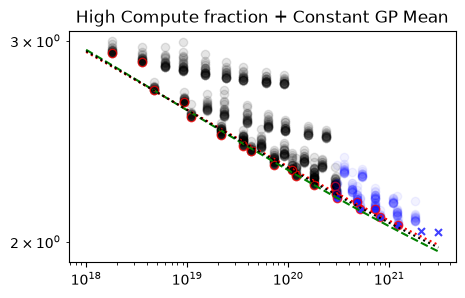

In [29]:
plt.clf()

plt.figure(figsize=(5,3))

# mark observed points
plt.scatter(train_df["flops"], train_df["loss"], color="black", label="observed points", alpha=0.1)
plt.scatter(_train_pareto["flops"], _train_pareto["loss"], color="black", label="observed pareto", alpha=0.75, edgecolor="red")

# mark test points
plt.scatter(test_df_known["flops"], test_df_known["loss"], color="blue", label="val. points", alpha=0.05)
plt.scatter(_test_df_pareto["flops"], _test_df_pareto["loss"], color="blue", label="val. pareto", alpha=0.75, edgecolor="red")
plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")

# comparing predictions
_flops = np.logspace(18, np.log10(global_test_pareto["flops"].max()), 100)

plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _best_params),
    color="green", label="observed data fit", linestyle="--"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _fant_best_params),
    color="red", label="observed + predicted data fit", linestyle=":"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, global_data_params),  #all_data_params),
    color="black", label="train data fit", linestyle=":"
)
# plt.plot(
#     _flops,
#     model.predict(np.log(_flops)[:, None]),
#     color="orange", label="GP prediction", linestyle="-"
# )
# plt.plot(
#     _flops,
#     fant_model.predict(np.log(_flops)[:, None]),
#     color="purple", label="Fantasized GP prediction", linestyle="-."
# )

plt.xscale("log")
plt.yscale("log")
# plt.legend(ncol=2, loc="upper left")
plt.title(f"High Compute fraction + Constant GP Mean")

plt.savefig(PLOT_PATH / f"high_C_std_gp.pdf", dpi=300, bbox_inches="tight")

#### Changing GP Mean

In [30]:
# build GP
_pred, _mse, model = build_surrogate(
    np.log(_train_pareto[INPUTS].values),
    _train_pareto.loss.to_numpy()[:, None],
    np.log(global_test_pareto[INPUTS].values),
    model_type="gp",
    mean_form="L0",
)
print(_pred)

### on observed + predicted data
_fantasized_pred = model.predict(np.log(test_df_known[INPUTS].values))

_new_df = pd.concat((train_df, test_df_known.assign(loss=_fantasized_pred.flatten())))
_new_df_pareto = get_pareto_frontier(
    _new_df,
    x_name="flops",
    y_name="loss",
)

# refitting
fant_pred, fant_mse, fant_model = build_surrogate(
    np.log(_new_df_pareto[INPUTS].values),
    _new_df_pareto.loss.values[:, None],
    np.log(global_test_pareto[INPUTS].values),
    model_type="gp",
    mean_form="L0",
)
print(fant_pred)

# reftting parametric form
_fant_train_pareto = get_pareto_frontier(
    _new_df,
    x_name="flops",
    y_name="loss",
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_train_pareto["flops"].values, _fant_train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
) 
print(PARAMETRIC_FORMS["L0"].func(global_test_pareto["flops"].values, _fant_best_params))

print("=" * 50)
print(len(_train_pareto), len(_fant_train_pareto))
print(f"best params on observed data only: {_best_params}")
print(f"best params on observed + predicted data: {_fant_best_params}")

[2.01760683 1.9692584 ]
[2.02062411 1.99282725]
[1.99807642 1.96257785]
14 22
best params on observed data only: [ 1.38629436 10.84845108 -0.1963931 ]
best params on observed + predicted data: [ 1.38629436 10.80951578 -0.19551056]


In [31]:
# _print_fit_results(
#     PARAMETRIC_FORMS["L0"].func,
#     _fant_train_pareto)

/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_39500/1765127638.py:12: UserWarning: You passed an edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")


<Figure size 640x480 with 0 Axes>

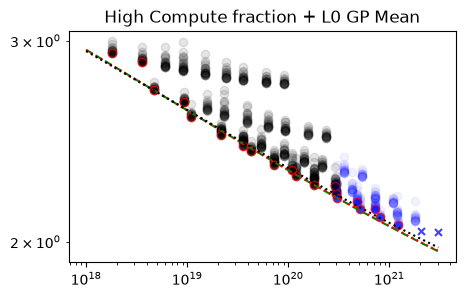

In [32]:
plt.clf()

plt.figure(figsize=(5,3))

# mark observed points
plt.scatter(train_df["flops"], train_df["loss"], color="black", label="observed points", alpha=0.1)
plt.scatter(_train_pareto["flops"], _train_pareto["loss"], color="black", label="observed pareto", alpha=0.75, edgecolor="red")

# mark test points
plt.scatter(test_df_known["flops"], test_df_known["loss"], color="blue", label="val. points", alpha=0.05)
plt.scatter(_test_df_pareto["flops"], _test_df_pareto["loss"], color="blue", label="val. pareto", alpha=0.75, edgecolor="red")
plt.scatter(global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red")

# comparing predictions
_flops = np.logspace(18, np.log10(global_test_pareto["flops"].max()), 100)

plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _best_params),
    color="green", label="observed data fit", linestyle="--"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, _fant_best_params),
    color="red", label="observed + predicted data fit", linestyle=":"
)
plt.plot(
    _flops,
    PARAMETRIC_FORMS["L0"].func(_flops, global_data_params),  #all_data_params),
    color="black", label="train data fit", linestyle=":"
)
# plt.plot(
#     _flops,
#     model.predict(np.log(_flops)[:, None]),
#     color="orange", label="GP prediction", linestyle="-"
# )
# plt.plot(
#     _flops,
#     fant_model.predict(np.log(_flops)[:, None]),
#     color="purple", label="Fantasized GP prediction", linestyle="-."
# )

plt.xscale("log")
plt.yscale("log")
# plt.legend(ncol=2, loc="upper right")
plt.title(f"High Compute fraction + L0 GP Mean")

# a common legend
# labels, handles = plt.gca().get_legend_handles_labels()
# by_label = dict(zip(labels, handles))
# plt.legend(by_label.values(), by_label.keys(), loc="lower left", ncol=1, fontsize=10)

plt.savefig(PLOT_PATH / f"high_C_L0_gp.pdf", dpi=300, bbox_inches="tight")

---

## GP vs. Parametric form

$L = L_0 + A \cdot C^\alpha$

In [77]:
# preprocess data
train_df, test_df_known, test_df_unknown = data_preprocess(
    df, held_out_type="C", held_out_C_lower=1/100
)
train_df.shape, test_df_known.shape, train_df.flops.max(), test_df_known.flops.max()

((251, 16), (639, 16), np.float64(2.4e+19), np.float64(3.06e+21))

In [78]:
SAMPLING_FRACTION = 0.5

train_df = train_df.sample(int(SAMPLING_FRACTION * len(train_df)))
train_df.shape

(125, 16)

In [79]:
# model building

# GP_MEAN_FORM = "L0"
# GP_MEAN_FORM = None  
GP_MEAN_FORM = "chinchilla3"

INPUTS = ["N", "D", "lr", "gbsz"]

_pred, _mse, model = build_surrogate(
    np.log(train_df[INPUTS].values),
    train_df.loss.to_numpy()[:, None],
    np.log(train_df[INPUTS].values),
    model_type="gp",
    mean_form=GP_MEAN_FORM,
    gp_kernel="linear+matern"
)

In [80]:
# Creating two compute levels here 

C1 = 5e19
C2 = 5e20
k = C2/C1
k

10.0

In [81]:
_df = df.loc[df.flops <= C1]
_df = _df.loc[_df.flops == _df.flops.max()]
_df = _df.groupby(["N", "D", "lr", "gbsz"]).loss.min()
HP1 = _df.index.values[np.argmin(_df.values)]
LOSS1 = min(_df.values)

_df = df.loc[df.flops <= C2]
_df = _df.loc[_df.flops == _df.flops.max()]
_df = _df.groupby(["N", "D", "lr", "gbsz"]).loss.min()
# print(_df)
# print()
HP2 = _df.index.values[np.argmin(_df.values)]
LOSS2 = min(_df.values)

print(C1, HP1, LOSS1, 6*HP1[0]*HP1[1])
print(C2, HP2, LOSS2, 6*HP2[0]*HP2[1])
print(train_df.flops.max(), train_df.loss.min())

5e+19 (588544000, 12000000000.0, 0.002, 128) 2.398821 4.2375168e+19
5e+20 (983138304, 80000000000.0, 0.0005, 128) 2.164629 4.7190638592e+20
2.4e+19 2.484436


In [82]:
GP_PRED, GP_STD = model.predict(np.log(np.vstack((HP1, HP2))), return_std=True)
print(GP_PRED, GP_STD)
LOSS1, LOSS2 

[2.41354876 2.16856649] [0.01215688 0.04534886]


(np.float64(2.398821), np.float64(2.164629))

In [83]:
# fit parametric form

_train_pareto = get_pareto_frontier(
    train_df,
    x_name="flops",
    y_name="loss",
)

_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _train_pareto["flops"].values, _train_pareto["loss"].values,
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)

_print_fit_results(PARAMETRIC_FORMS["L0"], _best_params)

L(C) = 4.000 + 435900.676 * C^(-0.2450)


In [84]:
_flops = np.array([6 * HP1[0] * HP1[1], 6 * HP2[0] * HP2[1]])
PARAMETRIC_FORMS["L0"].func(_flops, _best_params)

array([2.37732267, 2.04825322])

/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_39500/3513026422.py:16: UserWarning: You passed an edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(
/var/folders/my/4ds_24vn58q_p0nm757qmqyc0000gp/T/ipykernel_39500/3513026422.py:78: UserWarning: You passed an edgecolor/edgecolors ('red') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(


<Figure size 640x480 with 0 Axes>

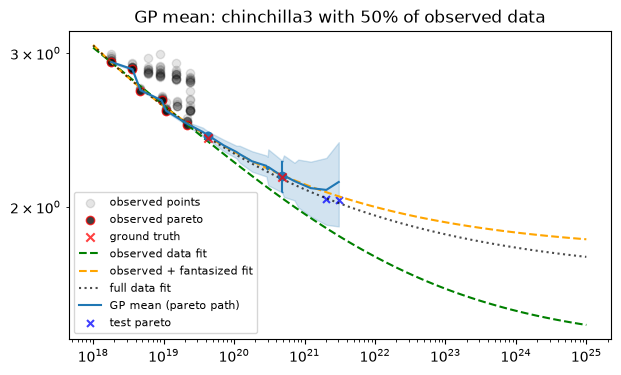

In [85]:
plt.clf()

plt.figure(figsize=(7,4))

plt.scatter(
    train_df["flops"], train_df["loss"], color="black", label="observed points", alpha=0.1
)
plt.scatter(
    _train_pareto["flops"], _train_pareto["loss"], color="black", label="observed pareto", alpha=0.75, edgecolor="red"
)

# GP preds with std. dev.
plt.errorbar(_flops, GP_PRED, yerr=2 * GP_STD, fmt="o", capsize=1)

# Ground truth
plt.scatter(
    _flops, [LOSS1, LOSS2], color="red", label="ground truth", alpha=0.75, edgecolor="black", marker="x", zorder=10,
)

_floplist = np.logspace(18, 25, 100)
plt.plot(
    _floplist,
    PARAMETRIC_FORMS["L0"].func(_floplist, _best_params),
    color="green", label="observed data fit", linestyle="--"
)

# fantasize held-out losses with the GP, then refit the parametric form on observed + fantasized
known_test_pareto = get_pareto_frontier(test_df_known, x_name="flops", y_name="loss")

_fantasized_pred = model.predict(np.log(test_df_known[INPUTS].to_numpy()))  # GP mean only
_fant_df = test_df_known.assign(loss=_fantasized_pred.flatten())

_fant_pareto = get_pareto_frontier(
    pd.concat((train_df, _fant_df)), x_name="flops", y_name="loss"
)
_fant_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _fant_pareto["flops"].values, np.log(_fant_pareto["loss"].values),   # func returns log-L
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
plt.plot(
    _floplist,
    PARAMETRIC_FORMS["L0"].func(_floplist, _fant_best_params, return_log_loss=False),
    color="orange", label="observed + fantasized fit", linestyle="--"
)

# ground-truth parametric fit on ALL data (train + known test)
_full_df = pd.concat((train_df, test_df_known))
_full_pareto = get_pareto_frontier(_full_df, x_name="flops", y_name="loss")
_full_best_params, _, _ = fit_parametric_form(
    PARAMETRIC_FORMS["L0"].func,
    _full_pareto["flops"].values, np.log(_full_pareto["loss"].values),   # func returns log-L
    initial_grid=PARAMETRIC_FORMS["L0"].initial_grid("debug"),
    bounds=PARAMETRIC_FORMS["L0"].bounds,
)
plt.plot(
    _floplist,
    PARAMETRIC_FORMS["L0"].func(_floplist, _full_best_params, return_log_loss=False),
    color="black", label="full data fit", linestyle=":", alpha=0.7
)


# tracking mean and std. dev. of GP along the pareto path (observed + known test)
known_test_pareto = get_pareto_frontier(
    test_df_known,
    x_name="flops",
    y_name="loss",
)
_pareto = pd.concat((_train_pareto, known_test_pareto)).drop_duplicates().sort_values("flops")
_pareto_x = np.log(_pareto[INPUTS].to_numpy())
mu, sd = model.predict(_pareto_x, return_std=True)
order = np.argsort(_pareto["flops"].values)
fx = _pareto["flops"].values[order]
plt.plot(fx, mu[order], color="tab:blue", label="GP mean (pareto path)")
plt.fill_between(fx, (mu-2*sd)[order], (mu+2*sd)[order], color="tab:blue", alpha=0.2)

plt.scatter(
    global_test_pareto["flops"], global_test_pareto["loss"], color="blue", marker="x", s=25, label="test pareto", alpha=0.75, edgecolor="red"
)

plt.xscale("log")
plt.yscale("log")

plt.title(f"GP mean: {'constant' if GP_MEAN_FORM is None else GP_MEAN_FORM} with {SAMPLING_FRACTION*100:.0f}% of observed data")
plt.legend(loc="lower left", ncol=1, fontsize=8)

plt.savefig(PLOT_PATH / f"gp_mean_{'constant' if GP_MEAN_FORM is None else GP_MEAN_FORM}_{int(SAMPLING_FRACTION*100)}pct.pdf", dpi=300, bbox_inches="tight")

In [86]:
_fant_best_params, _full_best_params

(array([ 0.57425484,  8.130382  , -0.19004214]),
 array([ 0.50828758,  7.37644647, -0.1698894 ]))

In [43]:
# 1. GP mean vs ground truth
# 2. this seems to depend on observation set (untuitively)
# 3. the quality of parametric fit depends on observation set
# 4. GP mean+std gives some signal on how far we should collect our next point or estimates (depends on GP configuration)
# 5. Additional info comes through fantasization until C1 and then fitting the parameters (red line not there currently)

In [44]:
HP1, HP2

((588544000, 12000000000.0, 0.002, 128),
 (983138304, 80000000000.0, 0.0005, 128))

In [45]:
sorted(df.lr.unique()), sorted(df.gbsz.unique())
train_df.N.unique(), train_df.D.unique()

(array([ 47557632, 301880320, 124455168, 588544000]),
 array([2.0e+10, 6.0e+09, 8.0e+10, 1.2e+10, 3.0e+10, 5.0e+10]))